# Korpus aufbauen

In [2]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")


[('c:\\workspace\\nlp-lernen\\korpus', [], ['aanrud_sidsel_langroeckchen.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'alarcon-Der Dreispitz.txt', 'alberti-Japanische Märchen.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'kafka-landarzt.txt', 'kafka-urteil.txt', 'kafka-verwandlung.txt', 'schiller-raeuber.txt', 'Skowronnek-Sturmzeichen.txt', 'westermann-Die Nutzpflanzen unserer Kolonien und ihre wirtschaftliche Bedeutung für das Mutterland.txt'])]
17 Texte wurden erfolgreich in den Korpus geladen.


In [3]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(text, sprache='de_DE'):
    dic = pyphen.Pyphen(lang=sprache)
    worte = text.split()
    #print(worte)
    silben_gesamt = 0
    global syll1
    syll1 = 0
    
    for wort in worte:
        silben = dic.inserted(wort).split('-')
        #print(silben, len(silben))
        if len(silben) == 1:
            syll1 += 1
            #print("Silbe hier:",len(silben),"---->",silben)
        silben_gesamt += len(silben)

    return silben_gesamt

def avg_syllables_per_word(var3):
    #print("Übermittel var3:",var3)
    words = re.findall(r'\b\w+\b', var3.lower())
    avg_syllables = syllables_count(var3) / len(words)
    #print("Silben:",syllables_count(var3))
    #print("Wörter:",len(words))
    return round(avg_syllables, 1)

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)

def wiener_sachtext_formel(text):
    syll = 0
    ms = 0 
    sl = 0
    iw = 0
    es = 0
    words6 = 0
    global syll1

    if syllables_count(text) > 3:
        syll += 1
    ms = syll / number_words(text) * 100
    sl = avg_sen_len(text)

    words = re.findall(r'\b\w+\b', text.lower())
    for word in words:
        if len(word) > 5:
            #print("hier:",len(word),"---->",word)
            words6 += 1
    iw = words6 / number_words(text)
    es = syll1 / number_words(text) * 100
    # print("MS:",ms)
    # print("SL:",sl)
    # print("SL:",sl)
    # print("IW:",iw)
    # print("ES:",es)

    # print("syll1:",syll1)
    # print("# Words:",number_words(text))
    #print("Formel: 0.1935 *", ms,"+ 0.1672 *", sl,"+ 0.1297 *", iw,"- 0.0327 *", es," - 0.875")

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf,2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\textstat\textstat.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [68]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(analyzer='word', ngram_range=(1, 2), binary=True)
X = vectorizer.fit_transform(corpus)

In [ ]:
dist_matrix = cosine_distances(X)

for i, text in enumerate(corpus):
    print(f"Vektor für Text {i} →",
          X[i].toarray().reshape(-1)[:37]) 

print("\nCosine-Distanz-Matrix:")
print(dist_matrix)

Vektor für Text 0 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 1 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0]
Vektor für Text 2 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]
Vektor für Text 3 → [0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 4 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 5 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 6 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 7 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 8 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 9 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 10 → [0 0 0 0 0 0 0 0 0 

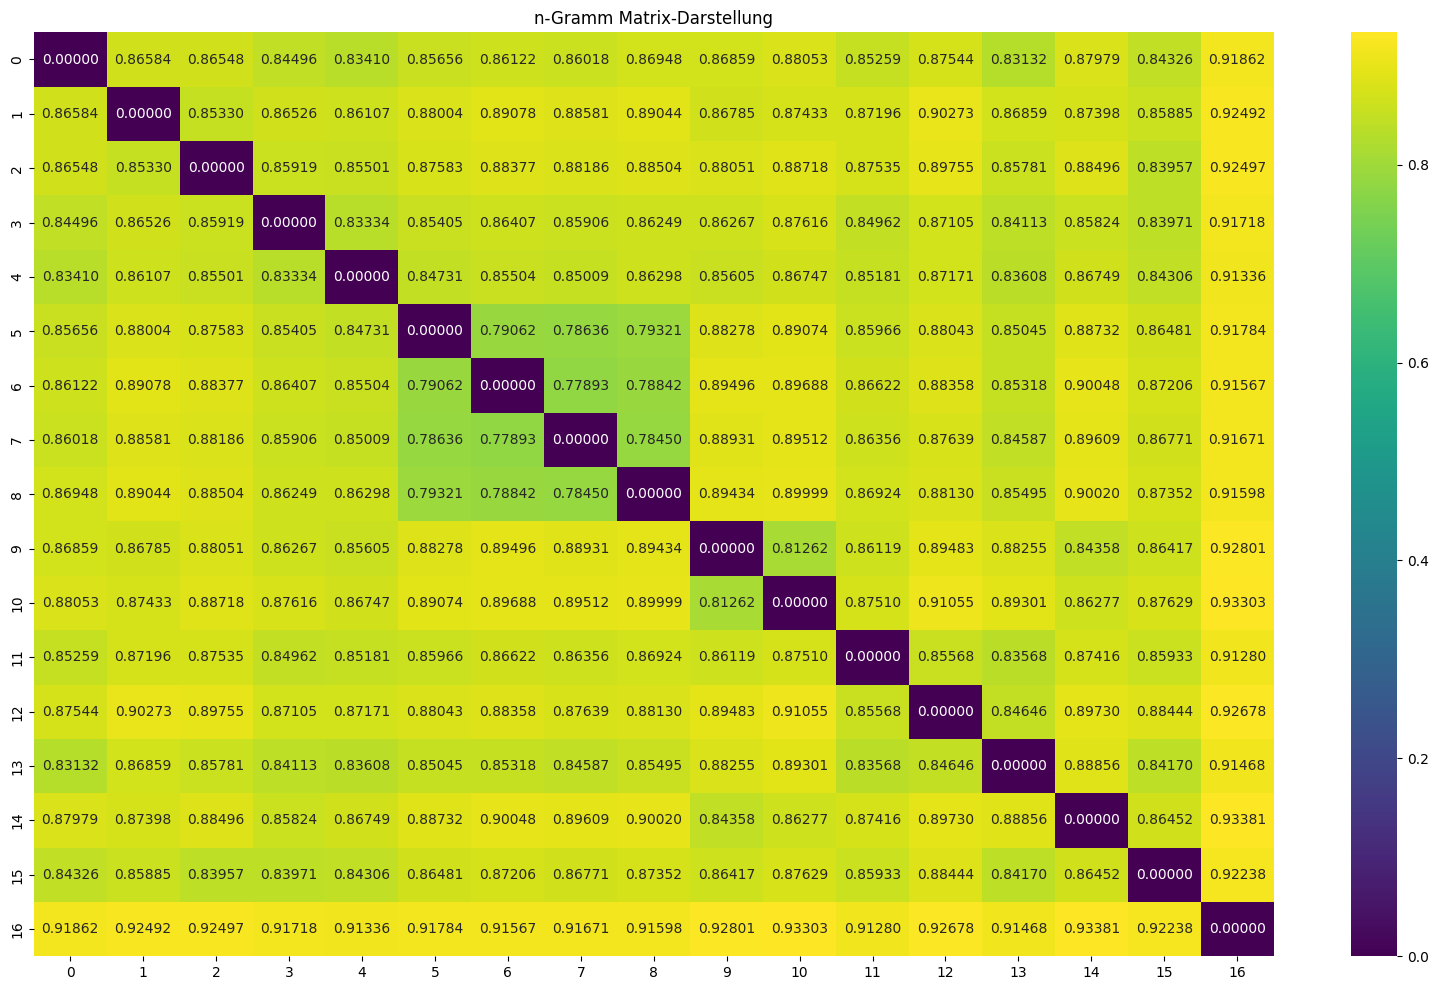

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(dist_matrix)

plt.figure(figsize=(20, 12))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("n-Gramm Matrix-Darstellung")
plt.show()


In [4]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    #corpus_list.append([number_sentences, number_words, avg_sen_len, avg_word_len, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

27616 1213
4.8 22.8 1.6 1.11 0.14
Anzahl eindeutiger Bigramme: 18890
Anzahl eindeutiger Trigramme: 28929

Top 5 Bigramme:
(',', 'und') → 336 Mal
(',', 'daß') → 194 Mal
(',', 'die') → 161 Mal
(',', 'als') → 107 Mal
(',', 'das') → 88 Mal

Top 5 Trigramme:
(',', 'daß', 'sie') → 68 Mal
('*', '*', '*') → 56 Mal
(',', 'als', 'sie') → 27 Mal
('.', 'ja', ',') → 24 Mal
(',', 'daß', 'er') → 22 Mal
None
-----------------------------------------------
54302 2749
5.3 19.8 1.7 0.72 0.17
Anzahl eindeutiger Bigramme: 41596
Anzahl eindeutiger Trigramme: 59601

Top 5 Bigramme:
('!', '“') → 433 Mal
(',', 'und') → 342 Mal
('“', '„') → 292 Mal
(',', 'die') → 257 Mal
(',', 'daß') → 220 Mal

Top 5 Trigramme:
('!', '“', '„') → 186 Mal
('*', '*', '*') → 132 Mal
('?', '“', '„') → 80 Mal
('.', '*', '*') → 38 Mal
(',', 'daß', 'die') → 34 Mal
None
-----------------------------------------------
63931 4079
5.5 15.7 1.8 0.18 0.15
Anzahl eindeutiger Bigramme: 46688
Anzahl eindeutiger Trigramme: 69058

Top 5 Bigramme:

In [5]:
corpus_vec = np.array(corpus_list)
corpus_matrix = cosine_distances(corpus_vec)

In [37]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 1.63042312e-03, 9.73723179e-03, 6.57894978e-04,
        9.80495887e-05, 8.83349290e-03, 7.77508344e-03, 7.15103671e-03,
        1.18176575e-02, 7.64862161e-02, 1.52136390e-02, 3.14750920e-04,
        6.71213972e-04, 1.12108250e-03, 3.02177190e-02, 4.89587791e-03,
        2.50416279e-02],
       [1.63042312e-03, 0.00000000e+00, 3.42096176e-03, 2.28948091e-04,
        2.33300477e-03, 2.90759038e-03, 2.29697035e-03, 1.96981329e-03,
        4.70376669e-03, 5.72891288e-02, 7.14684892e-03, 5.30661360e-04,
        2.59791611e-04, 5.14089765e-03, 1.83717495e-02, 9.29055320e-04,
        1.40393650e-02],
       [9.73723179e-03, 3.42096176e-03, 0.00000000e+00, 5.35066303e-03,
        1.13733648e-02, 3.39529044e-05, 1.17582764e-04, 2.09811706e-04,
        1.11069048e-04, 3.42625317e-02, 9.78352756e-04, 6.61866831e-03,
        5.39911926e-03, 1.68178226e-02, 6.49405953e-03, 8.77643609e-04,
        3.65105311e-03],
       [6.57894978e-04, 2.28948091e-04, 5.35066303e-03, 0.000

# Heatmap zeichnen

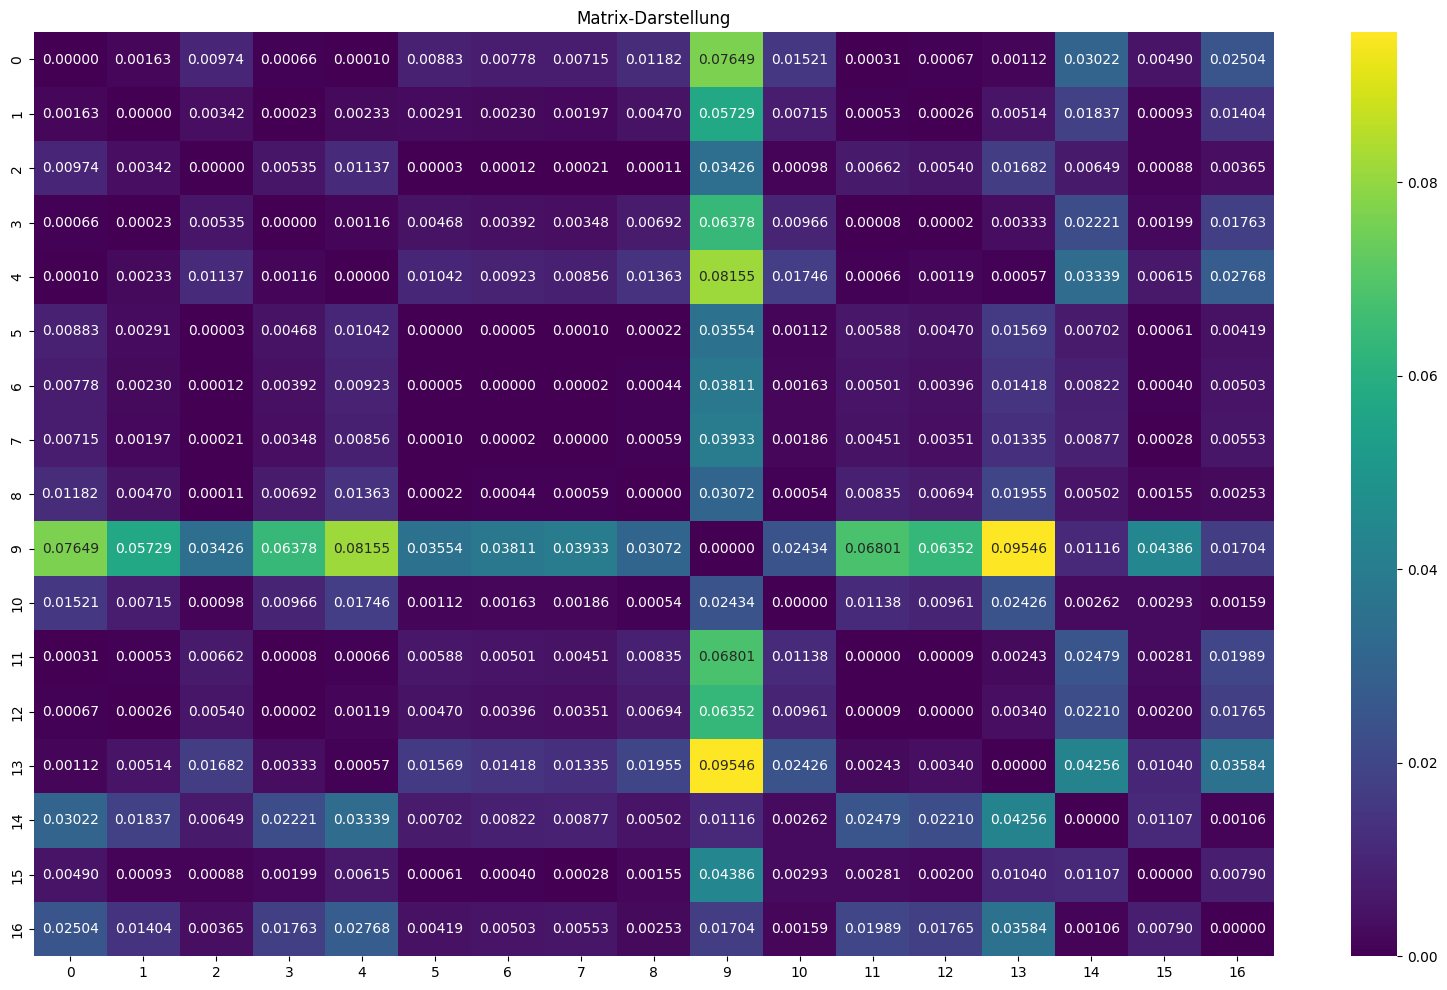

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(20, 12))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()


In [30]:
corpus_list

[[4.8, 22.8, 1.6, 1.11, 0.14],
 [5.3, 19.8, 1.7, 0.72, 0.17],
 [5.5, 15.7, 1.8, 0.18, 0.15],
 [5.0, 20.4, 1.7, 0.8, 0.17],
 [4.9, 24.2, 1.6, 1.45, 0.16],
 [5.4, 15.8, 1.8, 0.16, 0.2],
 [5.5, 16.4, 1.8, 0.29, 0.2],
 [5.4, 16.4, 1.8, 0.3, 0.21],
 [5.5, 15.1, 1.8, 0.07, 0.21],
 [4.8, 8.1, 1.5, -1.51, 0.16],
 [5.1, 13.6, 1.7, -0.39, 0.18],
 [5.1, 21.7, 1.7, 0.98, 0.23],
 [5.0, 20.5, 1.7, 0.74, 0.27],
 [5.1, 29.2, 1.7, 2.32, 0.17],
 [4.9, 11.1, 1.7, -0.81, 0.17],
 [5.2, 17.0, 1.7, 0.24, 0.14],
 [5.6, 12.9, 2.0, -0.29, 0.2]]

In [22]:
np.random.seed(42)
X = np.random.rand(100, 2)  # 100 samples, 2 features
print(type(X))

<class 'numpy.ndarray'>


Y: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
X_train: [[ 5.1  21.7   1.7   0.98  0.23]
 [ 4.9  11.1   1.7  -0.81  0.17]
 [ 5.5  15.1   1.8   0.07  0.21]
 [ 5.1  29.2   1.7   2.32  0.17]
 [ 5.5  15.7   1.8   0.18  0.15]
 [ 4.8   8.1   1.5  -1.51  0.16]
 [ 5.6  12.9   2.   -0.29  0.2 ]
 [ 4.9  24.2   1.6   1.45  0.16]
 [ 5.4  16.4   1.8   0.3   0.21]
 [ 5.1  13.6   1.7  -0.39  0.18]
 [ 5.   20.5   1.7   0.74  0.27]
 [ 5.   20.4   1.7   0.8   0.17]
 [ 5.5  16.4   1.8   0.29  0.2 ]]
X_test: [[ 4.8  22.8   1.6   1.11  0.14]
 [ 5.3  19.8   1.7   0.72  0.17]
 [ 5.4  15.8   1.8   0.16  0.2 ]
 [ 5.2  17.    1.7   0.24  0.14]]
y_train: [1 1 1 1 1 1 1 1 1 1 1 1 1]
y_test: [1 1 1 1]
y_pred: [1 1 1 1]
Accuracy: 1.0


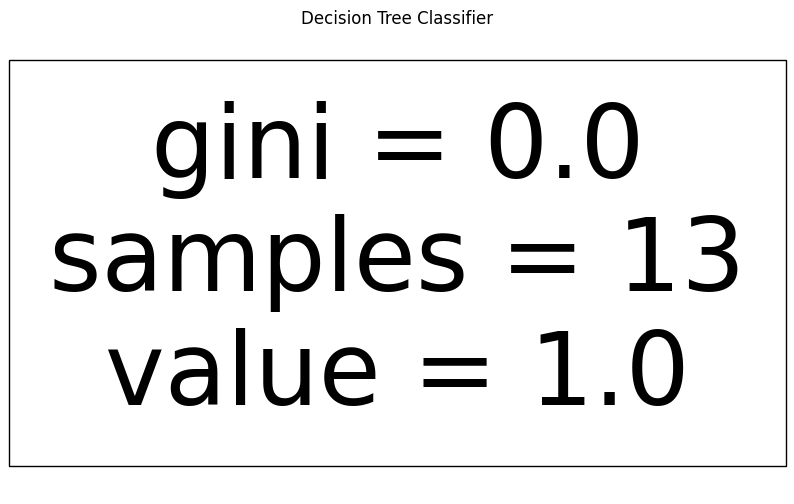

In [36]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn import tree

# Generate synthetic data
np.random.seed(42)
#X = np.random.rand(100, 2)  # 100 samples, 2 features
X = corpus_vec
#y = (X[:, 0] + X[:, 1] > 1).astype(int)  # Binary labels based on a linear combination of features
y = (X[:, 0] + X[:, 1] + X[:, 2] + X[:, 3] + X[:, 4] > 1).astype(int)

print("Y:",y)

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:",X_train)
print("X_test:",X_test)
print("y_train:",y_train)
print("y_test:",y_test)

# Create a Decision Tree Classifier model
model = DecisionTreeClassifier()

# Fit the model to the training data
model.fit(X_train, y_train)

# Make predictions on the testing set
y_pred = model.predict(X_test)

print("y_pred:",y_pred)

# Evaluate the model's accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Visualize the decision tree
plt.figure(figsize=(10, 6))
tree.plot_tree(model, filled=True, feature_names=['Feature 1', 'Feature 2'], class_names=['Class 0', 'Class 1'])
plt.title("Decision Tree Classifier")
plt.show()

In [58]:
corpus_list

[[4.8, 22.8, 1.6, 1.11, 0.14],
 [5.3, 19.8, 1.7, 0.72, 0.17],
 [5.5, 15.7, 1.8, 0.18, 0.15],
 [5.0, 20.4, 1.7, 0.8, 0.17],
 [4.9, 24.2, 1.6, 1.45, 0.16],
 [5.4, 15.8, 1.8, 0.16, 0.2],
 [5.5, 16.4, 1.8, 0.29, 0.2],
 [5.4, 16.4, 1.8, 0.3, 0.21],
 [5.5, 15.1, 1.8, 0.07, 0.21],
 [4.8, 8.1, 1.5, -1.51, 0.16],
 [5.1, 13.6, 1.7, -0.39, 0.18],
 [5.1, 21.7, 1.7, 0.98, 0.23],
 [5.0, 20.5, 1.7, 0.74, 0.27],
 [5.1, 29.2, 1.7, 2.32, 0.17],
 [4.9, 11.1, 1.7, -0.81, 0.17],
 [5.2, 17.0, 1.7, 0.24, 0.14],
 [5.6, 12.9, 2.0, -0.29, 0.2]]

In [115]:
# Load libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier # Import Decision Tree Classifier
from sklearn.model_selection import train_test_split # Import train_test_split function
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation
#col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
# load dataset
pima = pd.read_csv("diabetes.csv")
pima.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
#pd.to_numeric(pima["Pregnancies"])

In [118]:
#split dataset in features and target variable
feature_cols = ['Pregnancies', 'Insulin', 'BMI', 'Age','Glucose','BloodPressure','DiabetesPedigreeFunction']
X = pima[feature_cols] # Features
y = pima.Outcome # Target variable

In [119]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1) # 70% training and 30% test


In [120]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)


In [121]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.670995670995671


In [ ]:
from sklearn.tree import export_graphviz
from six import StringIO 
from IPython.display import Image  
import pydotplus

dot_data = StringIO()
export_graphviz(clf, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True,feature_names = feature_cols,class_names=['0','1'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('diabetes.png')
Image(graph.create_png())


-----------------------------------------------------------------

In [183]:
colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'TTR']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,TTR
0,4.8,22.8,1.6,1.11,0.14
1,5.3,19.8,1.7,0.72,0.17
2,5.5,15.7,1.8,0.18,0.15
3,5.0,20.4,1.7,0.80,0.17
4,4.9,24.2,1.6,1.45,0.16
5,5.4,15.8,1.8,0.16,0.20
6,5.5,16.4,1.8,0.29,0.20
7,5.4,16.4,1.8,0.30,0.21
8,5.5,15.1,1.8,0.07,0.21
9,4.8,8.1,1.5,-1.51,0.16


In [184]:
corp["Author"]= ["aanrud", "achleitner", "achleitner", "alarcon", "alberti", "anonymous", "anonymous", "anonymous", "anonymous", "goethe", "goethe", "kafka", "kafka", "kafka", "schuller", "skowronnek", "westermann"]
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,TTR,Author
0,4.8,22.8,1.6,1.11,0.14,aanrud
1,5.3,19.8,1.7,0.72,0.17,achleitner
2,5.5,15.7,1.8,0.18,0.15,achleitner
3,5.0,20.4,1.7,0.80,0.17,alarcon
4,4.9,24.2,1.6,1.45,0.16,alberti
5,5.4,15.8,1.8,0.16,0.20,anonymous
6,5.5,16.4,1.8,0.29,0.20,anonymous
7,5.4,16.4,1.8,0.30,0.21,anonymous
8,5.5,15.1,1.8,0.07,0.21,anonymous
9,4.8,8.1,1.5,-1.51,0.16,goethe


In [185]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [186]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1) # 70% training and 30% test


In [187]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)


In [188]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.3333333333333333


In [189]:
X = corp.iloc[:,0:5]
X

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,TTR
0,4.8,22.8,1.6,1.11,0.14
1,5.3,19.8,1.7,0.72,0.17
2,5.5,15.7,1.8,0.18,0.15
3,5.0,20.4,1.7,0.80,0.17
4,4.9,24.2,1.6,1.45,0.16
5,5.4,15.8,1.8,0.16,0.20
6,5.5,16.4,1.8,0.29,0.20
7,5.4,16.4,1.8,0.30,0.21
8,5.5,15.1,1.8,0.07,0.21
9,4.8,8.1,1.5,-1.51,0.16


In [190]:
y = corp.iloc[:,5]
y

0         aanrud
1     achleitner
2     achleitner
3        alarcon
4        alberti
5      anonymous
6      anonymous
7      anonymous
8      anonymous
9         goethe
10        goethe
11         kafka
12         kafka
13         kafka
14      schuller
15    skowronnek
16    westermann
Name: Author, dtype: object

In [191]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2)

In [192]:
X_train.shape

(13, 5)

In [193]:
X_test.shape

(4, 5)

In [194]:
y_train.shape

(13,)

In [195]:
y_test.shape

(4,)

In [196]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier()

In [197]:
dtc.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [198]:
dtc.fit(X_train, y_train)

DecisionTreeClassifier()

In [199]:
y_pred = dtc.predict(X_test)

In [200]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred))

[[0 0 0 1 0]
 [0 2 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 1 0 0]]


In [201]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     alarcon       0.00      0.00      0.00         1
   anonymous       1.00      1.00      1.00         2
      goethe       0.00      0.00      0.00         0
       kafka       0.00      0.00      0.00         0
    schuller       0.00      0.00      0.00         1

    accuracy                           0.50         4
   macro avg       0.20      0.20      0.20         4
weighted avg       0.50      0.50      0.50         4



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

In [202]:
dtc.feature_importances_

array([0.29340278, 0.12037037, 0.        , 0.18298611, 0.40324074])

In [203]:
X.columns

Index(['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables',
       'WienerSachtextFormel', 'TTR'],
      dtype='object')

In [204]:
features = pd.DataFrame(dtc.feature_importances_, index=X.columns)
features

,0
AverageWordLength,0.293403
AverageSentenceLength,0.120370
AverageSyllables,0.000000
WienerSachtextFormel,0.182986
TTR,0.403241


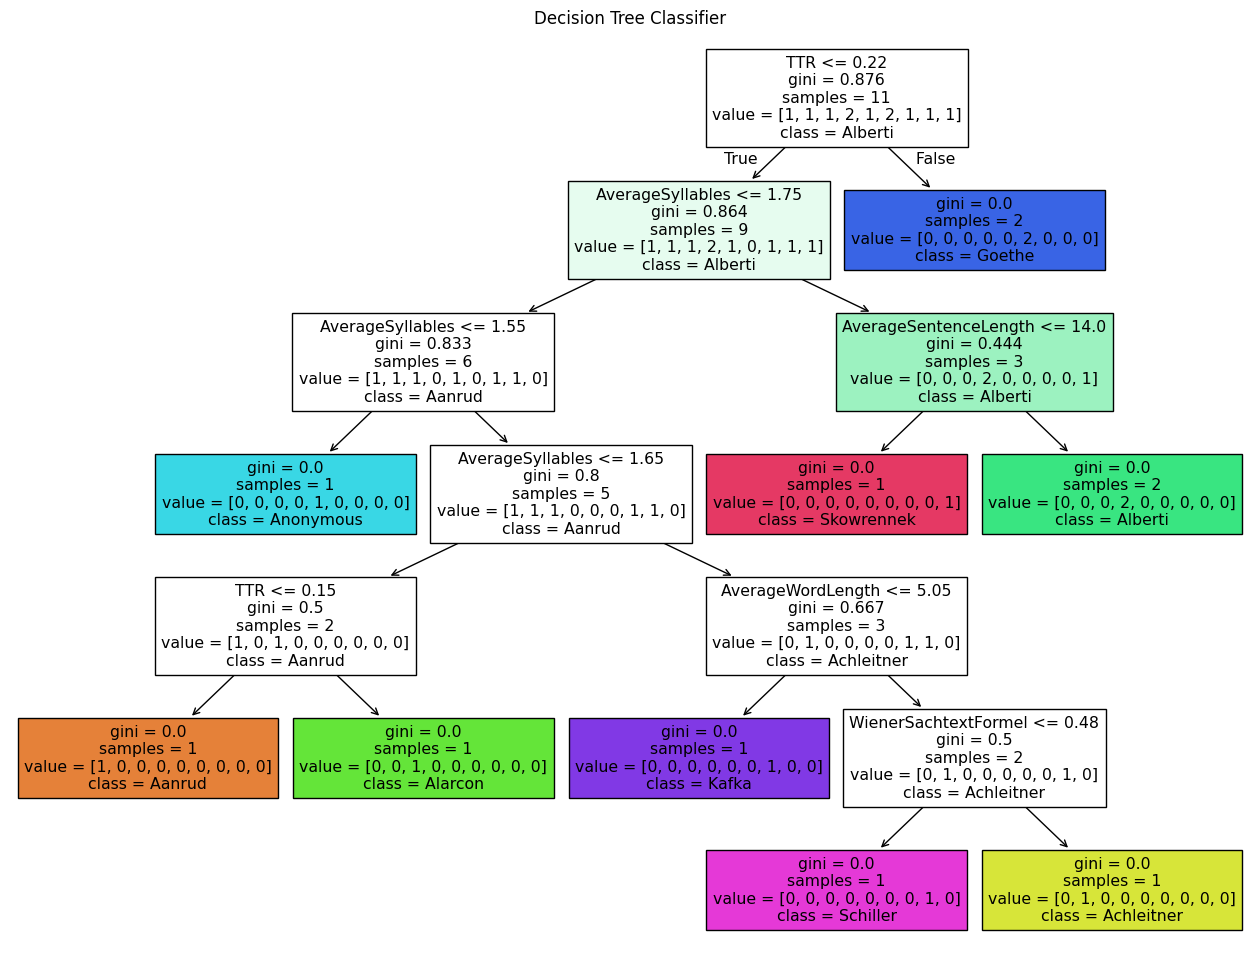

In [210]:
plt.figure(figsize=(16, 12))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Aanrud', 'Achleitner', 'Alarcon', 'Alberti', 'Anonymous', 'Goethe', 'Kafka', 'Schiller', 'Skowrennek', 'Westermann'])
plt.title("Decision Tree Classifier")
plt.show()
